# Lab 1: Telco Customer Churn Analysis

## 1. Introduction

This lab focuses on preprocessing and exploring the Telco Customer Churn dataset using Python. The purpose is to understand customer information and explore the relationship between customer characteristics, services, payment methods, and customer churn. The analysis includes data cleaning, checking data types, identifying missing values, and visualizing patterns related to churn.

## 2. Loading the Dataset

The dataset is loaded into a pandas DataFrame. A DataFrame is a table that stores data in rows and columns, making it easier to inspect and analyze.

In [1]:
import pandas as pd

# Load the dataset
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [2]:
# Display the first five rows
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Display the last five rows
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


### Interpretation of the Head and Tail

The `head()` output displays the first five customer records, while the `tail()` output displays the last five customer records. Both outputs help us inspect the dataset, confirm the column names, and check that the data has loaded correctly.

## 3. Data Preprocessing

Data preprocessing prepares the dataset for analysis. In this section, we will inspect the data types, convert the Churn column from Yes/No to 1/0, and check for missing values.

In [ ]:
# Convert Churn values from Yes/No to 1/0
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

# Display the updated Churn values
df["Churn"].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

In [7]:
# Check for blank values in TotalCharges
(df["TotalCharges"].str.strip() == "").sum()

np.int64(11)

In [8]:
# Convert TotalCharges to numeric values
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Count missing values in each column
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

**Handling Missing Values**

The dataset contained 11 missing values in the `TotalCharges` column. After checking these records, I found that all 11 customers had a tenure of zero months. Since they had zero months of recorded service, I replaced the missing `TotalCharges` values with 0. This allows us to continue the analysis without deleting these customer records. This treatment assumes that these customers had not accumulated any total charges.

## 4. Exploratory Data Analysis

Exploratory Data Analysis (EDA) helps us understand the dataset by examining its structure, summary statistics, and patterns. In this section, we will explore the number of records, the types of data, and the distribution of important variables.

In [13]:
# Display the number of rows and columns
df.shape

(7043, 21)

In [14]:
# Display the data type of each column
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object

In [15]:
# Display summary statistics for numerical columns
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304,0.265370
std,0.368612,24.559481,30.090047,2266.794470,0.441561
min,0.000000,0.000000,18.250000,0.000000,0.000000
25%,0.000000,9.000000,35.500000,398.550000,0.000000
50%,0.000000,29.000000,70.350000,1394.550000,0.000000
75%,0.000000,55.000000,89.850000,3786.600000,1.000000
max,1.000000,72.000000,118.750000,8684.800000,1.000000


### Interpretation of Summary Statistics

The dataset contains 7,043 customer records. The average customer tenure is approximately 32.37 months, and the average monthly charge is 64.76. The average total charge is 2,279.73. The mean of the `Churn` column is approximately 0.2654, indicating that about 26.54% of customers left the company. Also, approximately 16.21% of customers are senior citizens. These statistics provide an overview of customer characteristics and churn in the dataset.

In [16]:
# Count customers who stayed and customers who left
df["Churn"].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

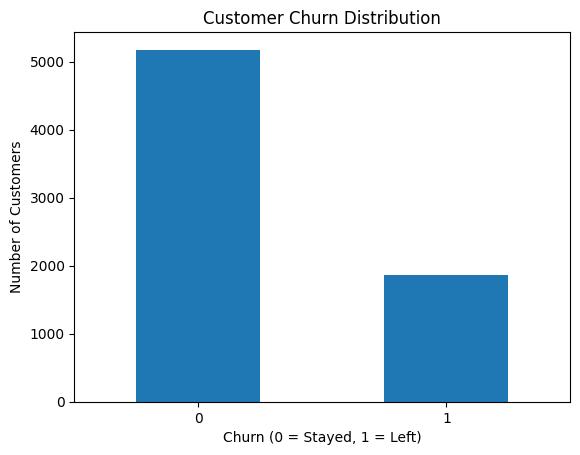

In [17]:
import matplotlib.pyplot as plt

# Count customers in each churn category
churn_counts = df["Churn"].value_counts().sort_index()

# Create a bar chart
churn_counts.plot(kind="bar")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = Stayed, 1 = Left)")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

### Interpretation of Churn Distribution

The bar chart shows that 5,174 customers stayed with the company, while 1,869 customers left. Therefore, most customers stayed, and approximately 26.54% left the company. This indicates that customer churn is an important area to investigate further.

In [18]:
# Calculate the average churn rate for each contract type
df.groupby("Contract")["Churn"].mean().mul(100)

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Churn, dtype: float64

### Interpretation of Churn by Contract Type

The analysis shows that customers with month-to-month contracts have the highest churn rate at approximately 42.71%. Customers with one-year contracts have a churn rate of 11.27%, while those with two-year contracts have the lowest rate at 2.83%. This suggests that customers with longer contracts are less likely to leave the company. The company could investigate ways to encourage customers to choose longer-term contracts.

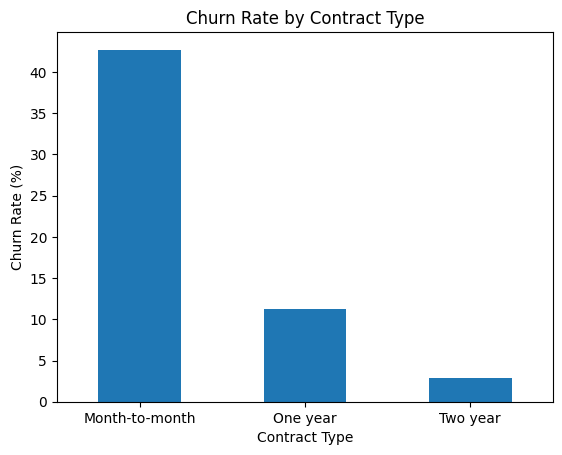

In [19]:
# Calculate churn rate for each contract type
contract_churn = df.groupby("Contract")["Churn"].mean() * 100

# Create a bar chart
contract_churn.plot(kind="bar")

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

In [20]:
# Calculate average monthly charges by churn status
df.groupby("Churn")["MonthlyCharges"].mean()

Churn
0    61.265124
1    74.441332
Name: MonthlyCharges, dtype: float64

In [27]:
# Load the original dataset again for checking
original_df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Convert blank TotalCharges entries to missing values
original_df["TotalCharges"] = pd.to_numeric(
    original_df["TotalCharges"], errors="coerce"
)

# Count missing values
print("Missing TotalCharges:", original_df["TotalCharges"].isnull().sum())

Missing TotalCharges: 11


In [29]:
# Reload the original dataset
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Convert Churn: Yes = 1, No = 0
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

# Remove rows containing missing values
df.dropna(inplace=True)

# Verify the cleaned dataset
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())

Dataset shape: (7032, 21)
Missing values: 0


### 5. Data Exploration

#### 5.1 Demographic Analysis

**Gender Distribution Against Churn**

This analysis compares male and female customers to understand how gender is related to customer churn.

In [31]:
# Compare gender with churn
pd.crosstab(df["gender"], df["Churn"])

Churn,0,1
gender,,
Female,2544,939
Male,2619,930


**Interpretation:**

The results show that 939 female customers and 930 male customers left the company. Meanwhile, 2,544 female customers and 2,619 male customers stayed. The number of customers who left is very similar for both genders. This suggests that gender alone may not be a strong indicator of customer churn.

**Senior Citizen Status Against Churn**

This analysis compares senior citizens and non-senior citizens to understand how senior citizen status is related to customer churn.

In [32]:
# Compare senior citizen status with churn
pd.crosstab(df["SeniorCitizen"], df["Churn"])

Churn,0,1
SeniorCitizen,,
0,4497,1393
1,666,476


**Interpretation:**

The results show that 1,393 non-senior citizens and 476 senior citizens left the company. Meanwhile, 4,497 non-senior citizens and 666 senior citizens stayed. Compared with non-senior citizens, senior citizens have a higher proportion of customers leaving the company. This suggests that senior citizen status may be related to customer churn.

**Partner Status Against Churn**

This analysis compares customers who have a partner with those who do not, to understand how partner status is related to customer churn.

In [33]:
# Compare partner status with churn
pd.crosstab(df["Partner"], df["Churn"])

Churn,0,1
Partner,,
No,2439,1200
Yes,2724,669


**Interpretation:**

The results show that 1,200 customers without partners left the company, compared with 669 customers who have partners. Among customers without partners, approximately 32.98% left, while approximately 19.71% of customers with partners left. This suggests that customers without partners have a higher churn rate than customers with partners.

In [34]:
# Compare dependent status with churn
pd.crosstab(df["Dependents"], df["Churn"])

Churn,0,1
Dependents,,
No,3390,1543
Yes,1773,326


**Phone Service Against Churn**

This analysis compares customers who have phone service with those who do not to understand how phone service is related to customer churn.

In [35]:
# Compare phone service with churn
pd.crosstab(df["PhoneService"], df["Churn"])

Churn,0,1
PhoneService,,
No,510,170
Yes,4653,1699


**Contract Against Churn**

This analysis compares customers with different contract types to understand how contract type is related to customer churn.

In [36]:
# Compare contract type with churn
pd.crosstab(df["Contract"], df["Churn"])

Churn,0,1
Contract,,
Month-to-month,2220,1655
One year,1306,166
Two year,1637,48


The results show that 1,655 customers with month-to-month contracts left the company, compared with 166 customers with one-year contracts and 48 customers with two-year contracts. The churn rates were approximately 42.71% for month-to-month contracts, 11.28% for one-year contracts, and 2.85% for two-year contracts. This suggests that customers with month-to-month contracts are more likely to leave, while customers with longer contracts are more likely to stay.

**Paperless Billing Against Churn**

This analysis compares customers who use paperless billing with those who do not to understand how billing preference is related to customer churn.

In [37]:
# Compare paperless billing with churn
pd.crosstab(df["PaperlessBilling"], df["Churn"])

Churn,0,1
PaperlessBilling,,
No,2395,469
Yes,2768,1400


The results show that 469 customers who did not use paperless billing left the company, compared with 1,400 customers who used paperless billing. The churn rate was approximately 16.38% for customers who did not use paperless billing and 33.59% for customers who used paperless billing. This suggests that customers who use paperless billing have a higher churn rate.

**Payment Method Against Churn**

This analysis compares customers using different payment methods to understand how payment method is related to customer churn.

In [39]:
# Compare payment method with churn
pd.crosstab(df["PaymentMethod"], df["Churn"])

Churn,0,1
PaymentMethod,,
Bank transfer (automatic),1284,258
Credit card (automatic),1289,232
Electronic check,1294,1071
Mailed check,1296,308


The results show that 258 customers using automatic bank transfer, 232 using automatic credit card, 1,071 using electronic check, and 308 using mailed check left the company. The churn rates were approximately 16.73% for automatic bank transfer, 15.25% for automatic credit card, 45.33% for electronic check, and 19.20% for mailed check. Customers using electronic checks had the highest churn rate, while customers using automatic credit cards had the lowest. This suggests that payment method is related to customer churn.